# Emotion Classification with Embedding Features

This notebook trains a classifier on the provided embedding pickle files and visualizes the results with charts.

## 1. Import Required Libraries

In [11]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.metrics import precision_score, recall_score

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

## 2. Load and Explore Data

Embedding counts: 9989 9989 9989
Label counts:
Emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64
Feature matrix shape: (9989, 3222)


C:\Users\admin\AppData\Local\Temp\ipykernel_41064\921173795.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')


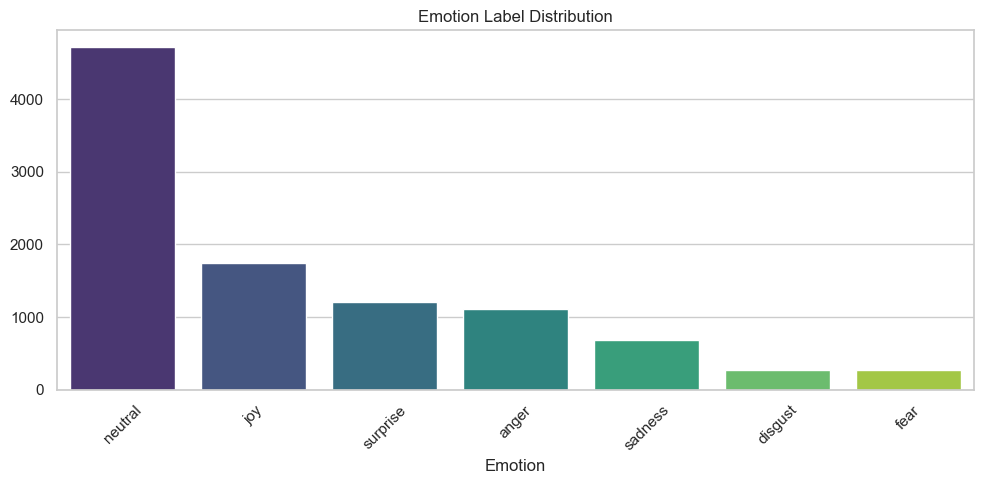

In [12]:
root = Path('.')
csv_path = root / 'train_sent_emo.csv'
audio_path = root / 'audi_embeddings.pkl'
text_path = root / 'text_embeddings.pkl'
reduced_path = root / 'text_encodings_reduced.pkl'

with audio_path.open('rb') as f:
    audio_embeddings = pickle.load(f)
with text_path.open('rb') as f:
    text_embeddings = pickle.load(f)
with reduced_path.open('rb') as f:
    reduced_embeddings = pickle.load(f)

df = pd.read_csv(csv_path)
df = df[['Utterance', 'Emotion']].dropna()
df = df[df['Utterance'].astype(str).str.strip() != '']

print('Embedding counts:', len(audio_embeddings), len(text_embeddings), len(reduced_embeddings))
print('Label counts:')
print(df['Emotion'].value_counts())

# Combine audio embeddings with reduced-text embeddings so the model learns from audio-informed features.
X_audio = np.vstack([np.array(x, dtype=float) for x in audio_embeddings])
X_text = np.vstack([np.array(x, dtype=float) for x in reduced_embeddings])
X = np.hstack([X_audio, X_text])
y = df['Emotion'].astype(str).to_numpy()

print('Feature matrix shape:', X.shape)

# Visualize label distribution
label_counts = df['Emotion'].value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')
plt.title('Emotion Label Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Prepare Data for Training

In [13]:
labels = sorted(set(y))
label_to_id = {label: idx for idx, label in enumerate(labels)}
y_num = np.array([label_to_id[label] for label in y])

X_train, X_test, y_train, y_test = train_test_split(
    X, y_num, test_size=0.2, random_state=42, stratify=y_num
)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

Train shape: (7991, 3222)
Test shape: (1998, 3222)


## 4. Build the Model

In [14]:
model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced_subsample',
    n_jobs=-1,
)

## 5. Train the Model

In [15]:
model.fit(X_train, y_train)
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

## 6. Evaluate Model Performance

In [16]:
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average='macro')
precision = precision_score(y_test, test_pred, average='macro', zero_division=0)
recall = recall_score(y_test, test_pred, average='macro', zero_division=0)

print('Train accuracy:', round(train_accuracy, 4))
print('Test accuracy:', round(test_accuracy, 4))
print('Macro F1:', round(test_macro_f1, 4))
print('Macro Precision:', round(precision, 4))
print('Macro Recall:', round(recall, 4))
print('Classification report:')
print(classification_report(y_test, test_pred, target_names=labels, zero_division=0))

Train accuracy: 1.0
Test accuracy: 0.4985
Macro F1: 0.151
Macro Precision: 0.3899
Macro Recall: 0.1754
Classification report:
              precision    recall  f1-score   support

       anger       1.00      0.00      0.01       222
     disgust       0.00      0.00      0.00        54
        fear       0.00      0.00      0.00        53
         joy       0.51      0.07      0.12       349
     neutral       0.49      0.99      0.66       942
     sadness       0.00      0.00      0.00       137
    surprise       0.73      0.17      0.27       241

    accuracy                           0.50      1998
   macro avg       0.39      0.18      0.15      1998
weighted avg       0.52      0.50      0.36      1998



## 7. Visualize Training History

C:\Users\admin\AppData\Local\Temp\ipykernel_41064\1583829585.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics, x='Split', y='Accuracy', palette='Set2')


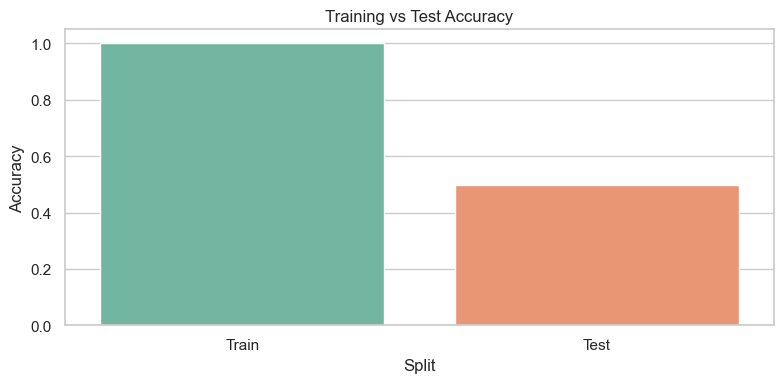

In [17]:
# Since this is a scikit-learn model, we show a compact performance summary chart.
metrics = pd.DataFrame({
    'Split': ['Train', 'Test'],
    'Accuracy': [train_accuracy, test_accuracy],
    'Macro F1': [f1_score(y_train, train_pred, average='macro'), test_macro_f1]
})

plt.figure(figsize=(8, 4))
sns.barplot(data=metrics, x='Split', y='Accuracy', palette='Set2')
plt.title('Training vs Test Accuracy')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()

## 8. Create Performance Charts

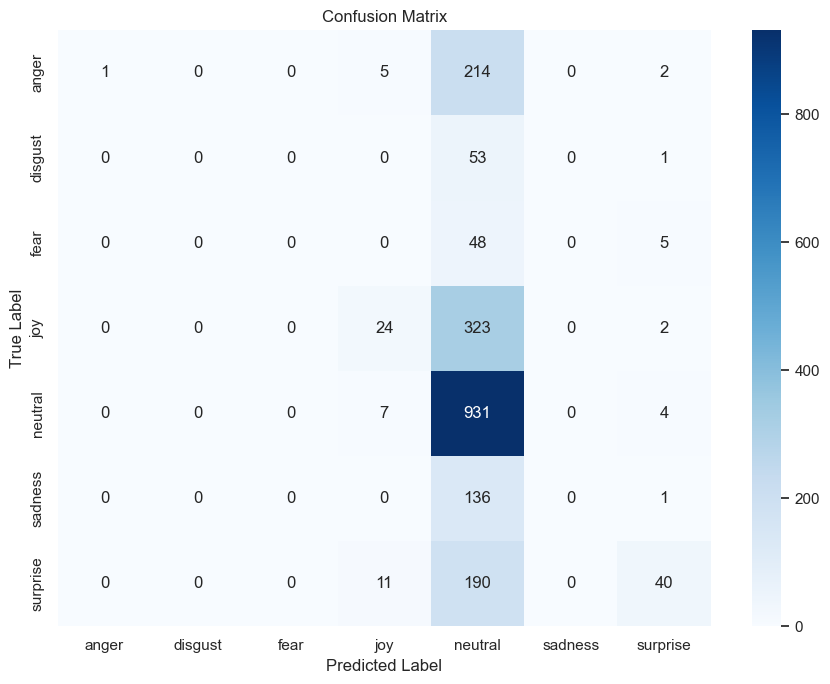

Saved confusion matrix to confusion_matrix.csv


In [18]:
cm = confusion_matrix(y_test, test_pred)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

cm_df.to_csv('confusion_matrix.csv')
print('Saved confusion matrix to confusion_matrix.csv')

## 9. Make Predictions and Visualize Results

C:\Users\admin\AppData\Local\Temp\ipykernel_41064\2623436076.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=result_df, x='Match', palette='pastel')


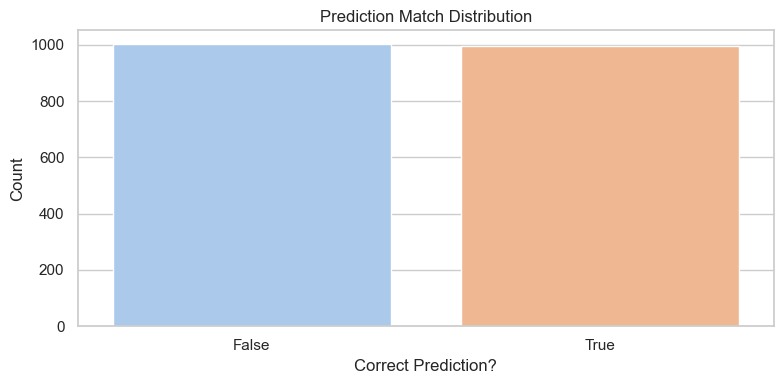

In [19]:
predicted_labels = [labels[i] for i in test_pred]
true_labels = [labels[i] for i in y_test]

result_df = pd.DataFrame({'True Label': true_labels, 'Predicted Label': predicted_labels})
result_df['Match'] = result_df['True Label'] == result_df['Predicted Label']

plt.figure(figsize=(8, 4))
sns.countplot(data=result_df, x='Match', palette='pastel')
plt.title('Prediction Match Distribution')
plt.xlabel('Correct Prediction?')
plt.ylabel('Count')
plt.tight_layout()
plt.show()